# AgentWeather: Exploratory Data Analysis (Hyderabad, Sindh)

- **Goal:** understand all six target metrics (AQI, temperature, precipitation, humidity, UV index, wind) before modelling.
- **Data:** Open-Meteo hourly weather and air quality, 2025-01-01 to 2026-11-11, UTC timestamps (Pakistan is UTC+5).
- **Questions:** Is the data complete? How strong is the naive 24h baseline? Which patterns should the features capture? Which alert thresholds make sense for Hyderabad?

## 1. Data overview

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw_history.csv", parse_dates=["time"], index_col="time")
print(df.shape)
df.describe().T

Matplotlib is building the font cache; this may take a moment.


(16320, 14)


,count,mean,std,min,25%,50%,75%,max
temperature_2m,16320.0,28.070135,6.940937,7.3,24.3,28.5,33.0,46.60
relative_humidity_2m,16320.0,52.964522,22.164550,4.0,36.0,52.0,72.0,99.00
precipitation,16320.0,0.016336,0.297759,0.0,0.0,0.0,0.0,12.50
wind_speed_10m,16320.0,12.287635,5.729755,0.0,7.9,12.3,16.7,31.10
wind_direction_10m,16320.0,202.325306,92.119022,1.0,205.0,224.0,240.0,360.00
surface_pressure,16320.0,1004.307065,7.021852,987.0,998.6,1003.9,1010.1,1022.30
us_aqi,16320.0,86.774326,22.930489,36.0,72.0,81.0,95.0,167.00
pm10,16320.0,53.587941,32.415535,4.3,32.7,46.4,66.1,560.70
pm2_5,16320.0,27.286115,13.749915,3.5,17.8,24.1,33.2,105.50
carbon_monoxide,16320.0,477.211887,413.500107,80.0,224.0,316.0,586.0,4083.00


**What I found:** I have 16,320 hourly rows and 14 columns, and nothing is missing. Some values are very high (PM10 reaches 560 and CO reaches 4,083), but I think these are dust events, so I'm keeping them.

## 2. How often does it rain?

In [2]:
rainy = (df["precipitation"] > 0.1)
print("Share of hours with rain above 0.1 mm:", round(rainy.mean() * 100, 2), "%")
print("Rainy days:", int(rainy.resample("D").max().sum()), "of", df.resample("D").size().shape[0])

Share of hours with rain above 0.1 mm: 0.97 %
Rainy days: 36 of 680


**What I found:** it rained (more than 0.1 mm) in less than 1% of hours, and only 36 days out of 680 had any rain. Hyderabad is very dry, so rain will be the hardest metric to predict.

## 3. Daily averages over time

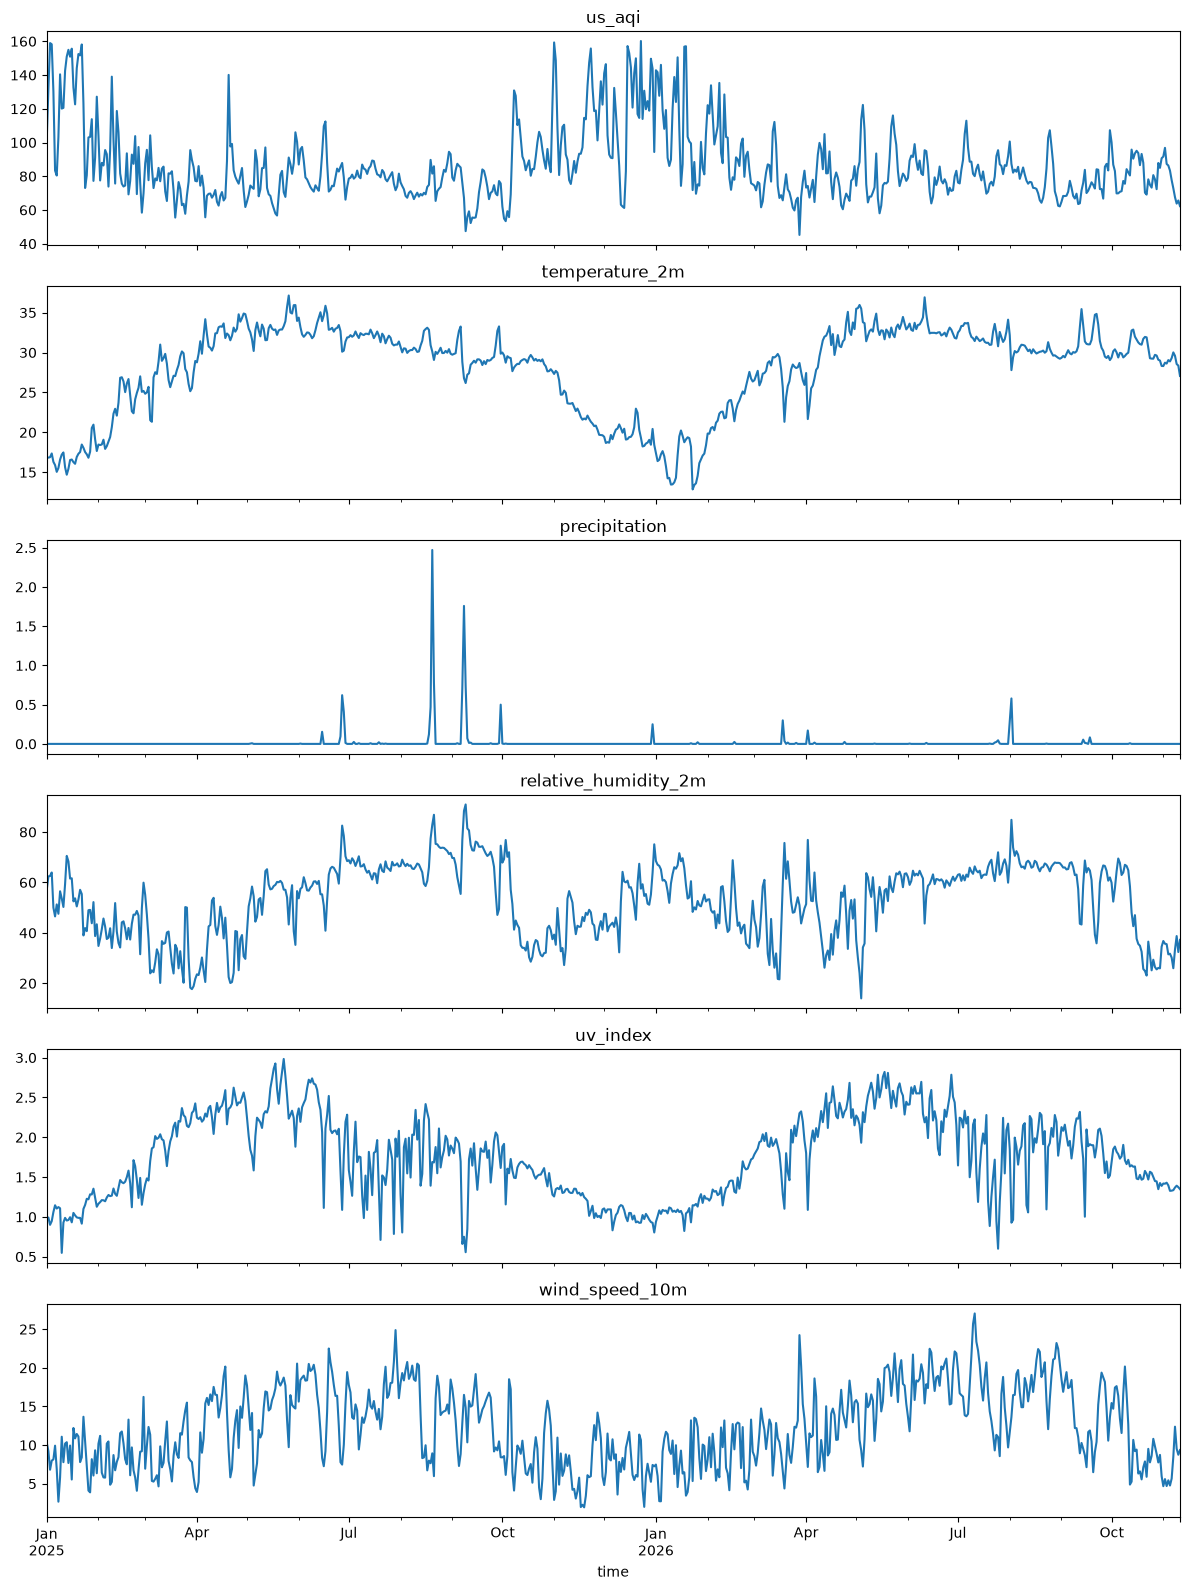

In [3]:
metrics = ["us_aqi", "temperature_2m", "precipitation",
           "relative_humidity_2m", "uv_index", "wind_speed_10m"]
fig, axes = plt.subplots(len(metrics), 1, figsize=(12, 16), sharex=True)
for ax, col in zip(axes, metrics):
    df[col].resample("D").mean().plot(ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**What I found:** temperature, humidity, UV and wind clearly repeat every year. AQI is worst in winter and better in the monsoon. Rain shows up as a few small spikes. UV looks low here only because the daily average includes the night, when UV is zero.

## 4. Naive baseline: "same value as 24 hours ago"

In [4]:
import numpy as np
metrics = ["us_aqi", "temperature_2m", "precipitation",
           "relative_humidity_2m", "uv_index", "wind_speed_10m"]

def scores(y_true, y_pred):
    err = y_true - y_pred
    rmse = np.sqrt((err ** 2).mean())
    mae = err.abs().mean()
    r2 = 1 - (err ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum()
    return rmse, mae, r2

rows = []
for m in metrics:
    base = df[m].shift(24)
    mask = base.notna()
    rows.append((m, *scores(df[m][mask], base[mask])))
pd.DataFrame(rows, columns=["metric", "RMSE", "MAE", "R2"]).round(3)

,metric,RMSE,MAE,R2
0,us_aqi,16.518,11.186,0.481
1,temperature_2m,1.462,0.997,0.956
2,precipitation,0.395,0.028,-0.761
3,relative_humidity_2m,10.710,6.989,0.767
4,uv_index,0.529,0.186,0.963
5,wind_speed_10m,4.468,3.341,0.393


**What I found:** just copying yesterday's value already works almost perfectly for UV and temperature (R² about 0.96), so there isn't much room to improve those. It works less well for humidity (0.77), AQI (0.48) and wind (0.39), so the models can help most there. For rain it's worse than guessing the average (-0.76).

## 5. Autocorrelation

In [5]:
lags = [1, 3, 6, 12, 24, 48, 72]
pd.DataFrame({m: [df[m].autocorr(l) for l in lags] for m in metrics},
             index=[f"{l}h" for l in lags]).round(3)

,us_aqi,temperature_2m,precipitation,relative_humidity_2m,uv_index,wind_speed_10m
1h,0.992,0.982,0.373,0.970,0.928,0.952
3h,0.949,0.862,0.349,0.795,0.470,0.859
6h,0.888,0.586,0.134,0.407,-0.216,0.770
12h,0.817,0.273,0.117,-0.062,-0.413,0.698
24h,0.741,0.978,0.119,0.883,0.981,0.696
48h,0.566,0.961,0.010,0.833,0.972,0.551
72h,0.502,0.951,0.000,0.807,0.968,0.488


**What I found:** temperature, humidity and UV are very similar at the same time each day (24h correlation above 0.88). AQI stays close to its recent past: 0.99 after 1 hour, 0.74 after 24 hours and 0.50 after 72 hours, so lag features should be useful. Rain has almost no memory after a few hours.

## 6. Daily pattern (hour of day, UTC)

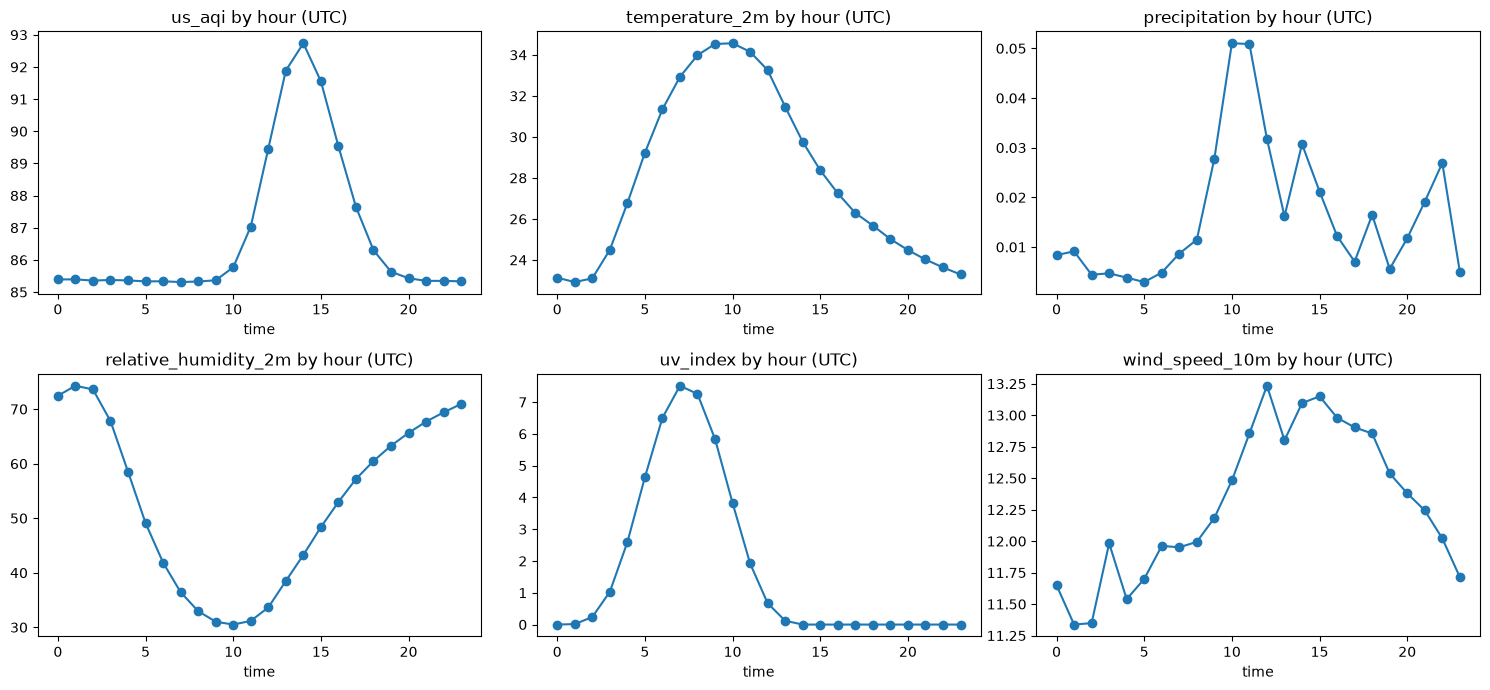

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, m in zip(axes.ravel(), metrics):
    df.groupby(df.index.hour)[m].mean().plot(ax=ax, marker="o")
    ax.set_title(m + " by hour (UTC)")
plt.tight_layout()
plt.show()

**What I found:** AQI stays flat for most of the day and then rises around 11:00 to 18:00 UTC, peaking at about 92.7 at 14:00 UTC, which is 7 PM in Pakistan (probably evening traffic). Temperature and UV peak around midday, and humidity goes the opposite way to temperature. So the hour of the day should be a feature.

## 7. Seasonal pattern (month)

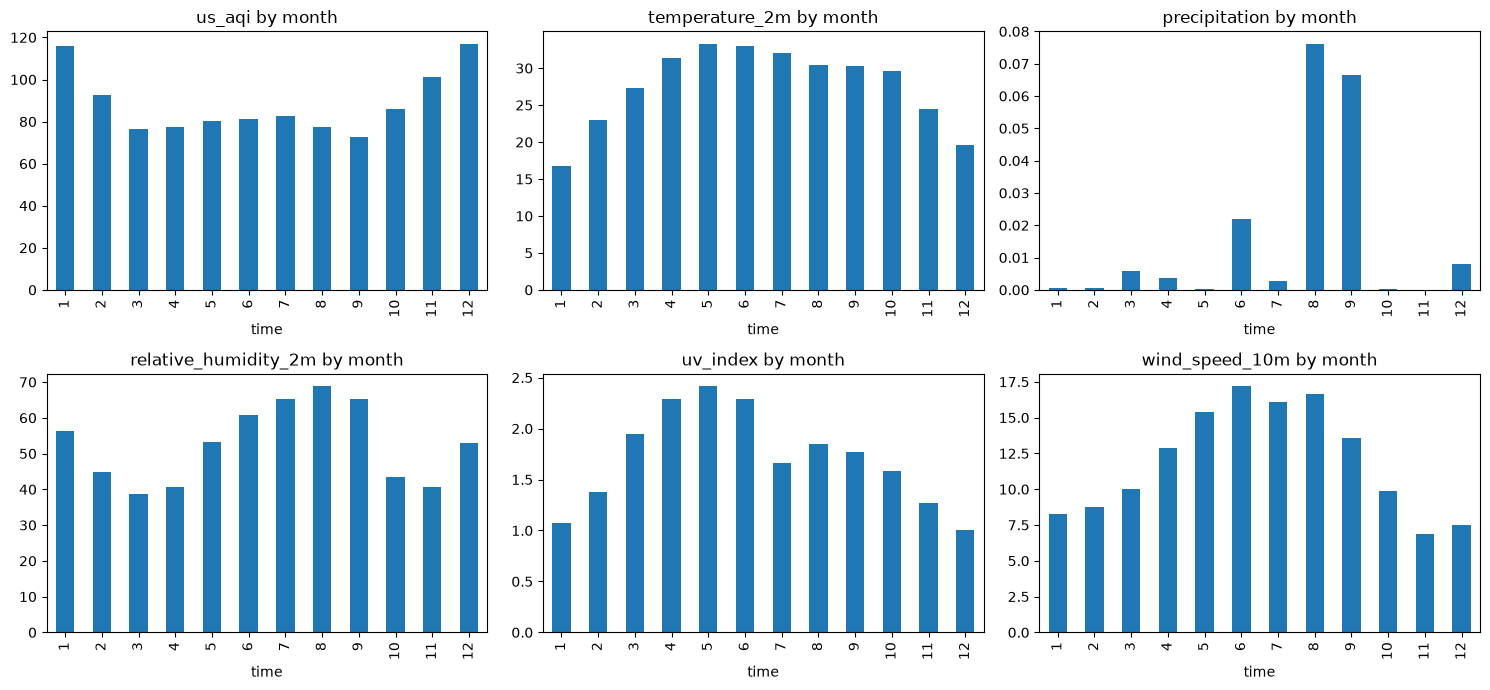

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, m in zip(axes.ravel(), metrics):
    df.groupby(df.index.month)[m].mean().plot(kind="bar", ax=ax)
    ax.set_title(m + " by month")
plt.tight_layout()
plt.show()

**What I found:** AQI is highest in December and January (about 115 to 117) and lowest from March to September (about 73 to 83). Temperature, UV and wind peak in summer, and rain and humidity peak in August and September. So the month should be a feature, and I need at least a full year of data to see this.

## 8. Correlation with AQI

In [9]:
df.corr()["us_aqi"].drop("us_aqi").sort_values().round(3)

temperature_2m         -0.379
wind_speed_10m         -0.357
wind_direction_10m     -0.256
uv_index               -0.129
relative_humidity_2m   -0.100
precipitation          -0.021
ozone                   0.102
pm10                    0.241
nitrogen_dioxide        0.327
surface_pressure        0.409
sulphur_dioxide         0.444
carbon_monoxide         0.450
pm2_5                   0.712
Name: us_aqi, dtype: float64

**What I found:** PM2.5 is the strongest link with AQI (+0.71), followed by CO, SO₂ and pressure (about +0.41 to +0.45). Temperature (-0.38) and wind (-0.36) go the other way, so cold, calm air gives the worst AQI. Part of the PM2.5 link is expected, because AQI is calculated from PM2.5.

## 9. Alert thresholds

In [10]:
def pct(mask):
    return round(mask.mean() * 100, 2)

print("AQI >=101:", pct(df.us_aqi >= 101), "%   >=151:", pct(df.us_aqi >= 151), "%")
print("Temp >=40:", pct(df.temperature_2m >= 40), "%   >=45:", pct(df.temperature_2m >= 45), "%")
print("UV >=6:", pct(df.uv_index >= 6), "%   >=8:", pct(df.uv_index >= 8), "%   >=11:", pct(df.uv_index >= 11), "%")
print("Wind >=20:", pct(df.wind_speed_10m >= 20), "%   >=25:", pct(df.wind_speed_10m >= 25), "%")
print("Rain >=2 mm/h:", pct(df.precipitation >= 2), "%   >=5 mm/h:", pct(df.precipitation >= 5), "%")

AQI >=101: 20.05 %   >=151: 3.08 %
Temp >=40: 2.86 %   >=45: 0.09 %
UV >=6: 11.52 %   >=8: 5.04 %   >=11: 0.1 %
Wind >=20: 9.5 %   >=25: 0.71 %
Rain >=2 mm/h: 0.23 %   >=5 mm/h: 0.1 %


**What I found:** AQI 101 or higher happens in 20% of hours and 151 or higher in 3.1%. Temperature of 40 °C or more happens in 2.9% of hours (45 °C in only 0.09%), UV of 6 or more in 11.5%, wind of 25 km/h or more in 0.7%, and heavy rain of 2 mm/h or more in 0.2%. I picked these so alerts are useful without firing all the time. The rare ones I'll test with made-up forecasts.

## 10. Rain target definition

In [11]:
hourly_rain = (df["precipitation"] > 0.1).astype(float)
print("A) rain in the single hour 24h ahead:", round(hourly_rain.mean() * 100, 2), "% of hours")

next24 = hourly_rain[::-1].rolling(24).max()[::-1].shift(-1)
print("B) any rain within the next 24h:", round(next24.mean() * 100, 2), "% of hours")

daily = df["precipitation"].resample("D").sum()
for t in [1, 5, 10]:
    print(f"Days with >= {t} mm:", int((daily >= t).sum()), "of", len(daily))
print("Max daily total (mm):", daily.max())

A) rain in the single hour 24h ahead: 0.97 % of hours
B) any rain within the next 24h: 5.47 % of hours
Days with >= 1 mm: 21 of 680
Days with >= 5 mm: 13 of 680
Days with >= 10 mm: 9 of 680
Max daily total (mm): 59.3


**Decision:** I'll predict "will it rain at any time in the next 24 hours". That happens in 5.5% of hours, compared to 0.97% for one specific hour, so it gives the model more rain examples to learn from. It's still very imbalanced, so I'll use class weights and judge it with F1 and ROC-AUC, not accuracy.

**Daily totals:** only 21 of 680 days have at least 1 mm of rain and 9 have at least 10 mm. The wettest day had 59.3 mm.

## What this means for the models
- The data is complete, and I'm keeping the extreme values.
- Yesterday's value is already very good for temperature and UV, so I'll focus on AQI, humidity and wind.
- Features to build: hour and month, AQI from 1, 6 and 24 hours ago, rolling averages, and rate of change.
- Rain will be a yes/no prediction for the next 24 hours. Rain in mm will score close to zero because the data is almost all zeros.
- Alert thresholds are based on Hyderabad's own data, as shown in cell 9.